<a href="https://colab.research.google.com/github/Samuel-1302/Teste-de-software/blob/main/Treinamento_IA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Bloco 1

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
URL_BASE = "https://raw.githubusercontent.com/williamasantos/Agente-de-Previsao-de-Conversao/refs/heads/preparacao-dados/digital_marketing_campaign_dataset.csv"
df_mkd = pd.read_csv(URL_BASE)
print(df_mkd.shape)   # deve mostrar (8000, 20)

(8000, 20)


#Bloco 2
## Descrição das Variáveis + Tipos de Dados

In [ ]:
df_mkd.head()

,CustomerID,Age,Gender,Income,CampaignChannel,CampaignType,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,AdvertisingPlatform,AdvertisingTool,Conversion
0,8000,56,Female,136912,Social Media,Awareness,6497.870068,0.043919,0.088031,0,2.399017,7.396803,19,6,9,4,688,IsConfid,ToolConfid,1
1,8001,69,Male,41760,Email,Retention,3898.668606,0.155725,0.182725,42,2.917138,5.352549,5,2,7,2,3459,IsConfid,ToolConfid,1
2,8002,46,Female,88456,PPC,Awareness,1546.429596,0.277490,0.076423,2,8.223619,13.794901,0,11,2,8,2337,IsConfid,ToolConfid,1
3,8003,32,Female,44085,PPC,Conversion,539.525936,0.137611,0.088004,47,4.540939,14.688363,89,2,2,0,2463,IsConfid,ToolConfid,1
4,8004,60,Female,83964,PPC,Conversion,1678.043573,0.252851,0.109940,0,2.046847,13.993370,6,6,6,8,4345,IsConfid,ToolConfid,1


In [ ]:
df_mkd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CustomerID           8000 non-null   int64  
 1   Age                  8000 non-null   int64  
 2   Gender               8000 non-null   object 
 3   Income               8000 non-null   int64  
 4   CampaignChannel      8000 non-null   object 
 5   CampaignType         8000 non-null   object 
 6   AdSpend              8000 non-null   float64
 7   ClickThroughRate     8000 non-null   float64
 8   ConversionRate       8000 non-null   float64
 9   WebsiteVisits        8000 non-null   int64  
 10  PagesPerVisit        8000 non-null   float64
 11  TimeOnSite           8000 non-null   float64
 12  SocialShares         8000 non-null   int64  
 13  EmailOpens           8000 non-null   int64  
 14  EmailClicks          8000 non-null   int64  
 15  PreviousPurchases    8000 non-null   i

Texto do Bloco 2 — Descrição das Variáveis + Tipos de Dados
A base possui 8.000 registros e 20 colunas, sem nenhum valor ausente (todas as colunas com 8.000 non-null). Cada linha representa um cliente exposto a campanhas de marketing digital. As variáveis se dividem em: dados demográficos (Age, Gender, Income), variáveis de marketing (CampaignChannel, CampaignType, AdSpend, ClickThroughRate, ConversionRate, AdvertisingPlatform, AdvertisingTool), engajamento do cliente (WebsiteVisits, PagesPerVisit, TimeOnSite, SocialShares, EmailOpens, EmailClicks) e histórico (PreviousPurchases, LoyaltyPoints). Quanto aos tipos, temos 5 colunas float64, 10 int64 e 5 object (texto/categóricas), ou seja, a base mistura dados numéricos e categóricos — diferente de bases totalmente numéricas. A variável-alvo é Conversion (0 = não converteu, 1 = converteu). A coluna CustomerID é apenas um identificador e não entra na análise.

#Bloco 3
##Dados Ausentes + Duplicatas + Outliers

In [ ]:
df_mkd.isnull().sum()


,0
CustomerID,0
Age,0
Gender,0
Income,0
CampaignChannel,0
CampaignType,0
AdSpend,0
ClickThroughRate,0
ConversionRate,0
WebsiteVisits,0


In [ ]:
(df_mkd.isnull().sum() / len(df_mkd)) * 100

,0
CustomerID,0.0
Age,0.0
Gender,0.0
Income,0.0
CampaignChannel,0.0
CampaignType,0.0
AdSpend,0.0
ClickThroughRate,0.0
ConversionRate,0.0
WebsiteVisits,0.0


In [ ]:
print(df_mkd.duplicated().sum())


0


In [ ]:
categoricas = df_mkd.select_dtypes(include='object')
for coluna in categoricas.columns:
    print(f"Coluna '{coluna}':")
    print(df_mkd[coluna].unique())
    print()


Coluna 'Gender':
['Female' 'Male']

Coluna 'CampaignChannel':
['Social Media' 'Email' 'PPC' 'Referral' 'SEO']

Coluna 'CampaignType':
['Awareness' 'Retention' 'Conversion' 'Consideration']

Coluna 'AdvertisingPlatform':
['IsConfid']

Coluna 'AdvertisingTool':
['ToolConfid']



In [ ]:
df_mkd = df_mkd.drop(columns=['AdvertisingPlatform', 'AdvertisingTool'])

In [ ]:
print(df_mkd.shape)
df_mkd.info()

(8000, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         8000 non-null   int64  
 1   Age                8000 non-null   int64  
 2   Gender             8000 non-null   object 
 3   Income             8000 non-null   int64  
 4   CampaignChannel    8000 non-null   object 
 5   CampaignType       8000 non-null   object 
 6   AdSpend            8000 non-null   float64
 7   ClickThroughRate   8000 non-null   float64
 8   ConversionRate     8000 non-null   float64
 9   WebsiteVisits      8000 non-null   int64  
 10  PagesPerVisit      8000 non-null   float64
 11  TimeOnSite         8000 non-null   float64
 12  SocialShares       8000 non-null   int64  
 13  EmailOpens         8000 non-null   int64  
 14  EmailClicks        8000 non-null   int64  
 15  PreviousPurchases  8000 non-null   int64  
 16  LoyaltyPoints

In [ ]:
numericas = df_mkd.select_dtypes(include='number').drop(columns=['CustomerID', 'Conversion'])

for coluna in numericas.columns:
    Q1 = df_mkd[coluna].quantile(0.25)
    Q3 = df_mkd[coluna].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    outliers = df_mkd[(df_mkd[coluna] < limite_inferior) | (df_mkd[coluna] > limite_superior)]
    print(f"{coluna}: {len(outliers)} outliers")


Age: 0 outliers
Income: 0 outliers
AdSpend: 0 outliers
ClickThroughRate: 0 outliers
ConversionRate: 0 outliers
WebsiteVisits: 0 outliers
PagesPerVisit: 0 outliers
TimeOnSite: 0 outliers
SocialShares: 0 outliers
EmailOpens: 0 outliers
EmailClicks: 0 outliers
PreviousPurchases: 0 outliers
LoyaltyPoints: 0 outliers


Verificamos a integridade da base: nenhum dado ausente, nenhuma linha duplicada e nenhum outlier (método IQR) — tudo zero. Nas variáveis categóricas, as categorias estão consistentes (ex.: Gender só "Female"/"Male"). Identificamos que AdvertisingPlatform e AdvertisingTool tinham um único valor em todas as linhas (colunas confidenciais e constantes); como não trazem informação útil, foram removidas, reduzindo a base de 20 para 18 colunas. Resultado: base íntegra e pronta para as análises seguintes.

#Bloco 4
##Estatísticas descritivas

In [ ]:
print(df_mkd.describe()
)

        CustomerID          Age         Income      AdSpend  ClickThroughRate  \
count   8000.00000  8000.000000    8000.000000  8000.000000       8000.000000   
mean   11999.50000    43.625500   84664.196750  5000.944830          0.154829   
std     2309.54541    14.902785   37580.387945  2838.038153          0.084007   
min     8000.00000    18.000000   20014.000000   100.054813          0.010005   
25%     9999.75000    31.000000   51744.500000  2523.221165          0.082635   
50%    11999.50000    43.000000   84926.500000  5013.440044          0.154505   
75%    13999.25000    56.000000  116815.750000  7407.989369          0.228207   
max    15999.00000    69.000000  149986.000000  9997.914781          0.299968   

       ConversionRate  WebsiteVisits  PagesPerVisit   TimeOnSite  \
count     8000.000000    8000.000000    8000.000000  8000.000000   
mean         0.104389      24.751625       5.549299     7.727718   
std          0.054878      14.312269       2.607358     4.228218  

O describe() mostrou que as variáveis numéricas têm faixas realistas e equilibradas, com médias próximas das medianas (ex.: AdSpend com média e mediana em torno de 5.000), indicando distribuições simétricas e sem valores distorcidos — o que reforça a ausência de outliers vista no Bloco 3. Age varia de 18 a 69 anos e Income de ~20 mil a ~150 mil USD. O principal achado está na variável-alvo Conversion: sua média de 0,88 revela que cerca de 88% dos clientes converteram e apenas ~12% não converteram, evidenciando um desbalanceamento de classes (a classe rara aqui é o "não converteu"), ponto que será analisado no bloco da variável-alvo e tratado na modelagem.

#Bloco 5
##Distribuição das principais variáveis

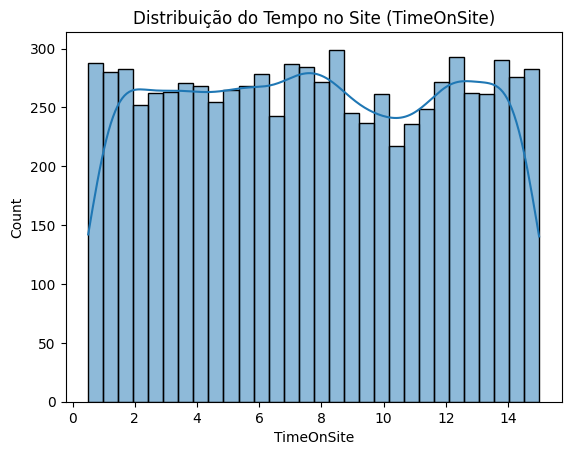

In [ ]:
sns.histplot(data=df_mkd, x='TimeOnSite', kde=True, bins=30)
plt.title('Distribuição do Tempo no Site (TimeOnSite)')
plt.show()


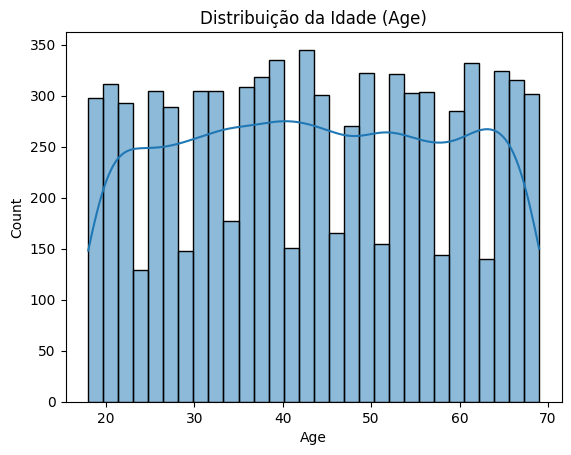

In [ ]:
sns.histplot(data=df_mkd, x='Age', kde=True, bins=30)
plt.title('Distribuição da Idade (Age)')
plt.show()


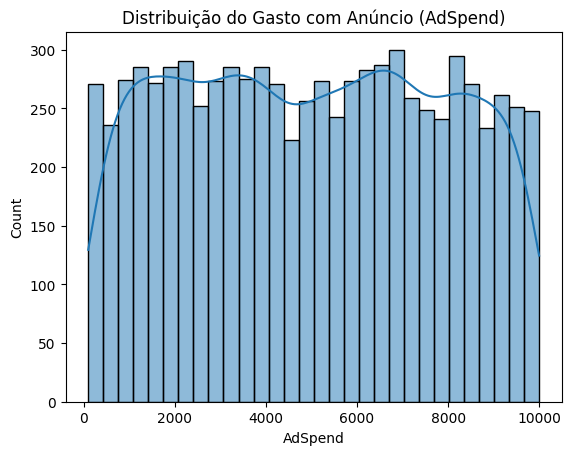

In [ ]:
sns.histplot(data=df_mkd, x='AdSpend', kde=True, bins=30)
plt.title('Distribuição do Gasto com Anúncio (AdSpend)')
plt.show()


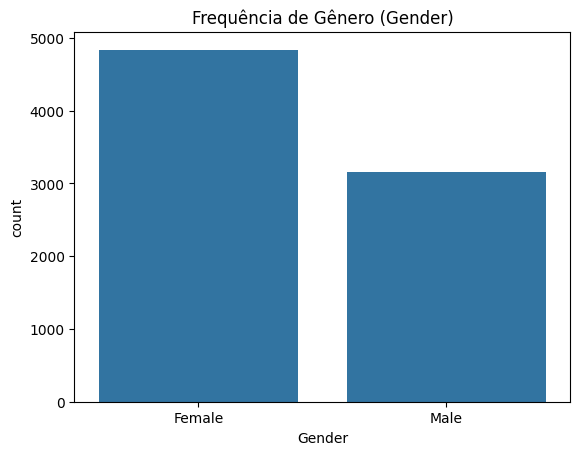

In [ ]:
sns.countplot(data=df_mkd, x='Gender')
plt.title('Frequência de Gênero (Gender)')
plt.show()


In [ ]:
df_mkd['CampaignChannel'].value_counts(normalize=True) * 100


,proportion
CampaignChannel,
Referral,21.4875
PPC,20.6875
Email,19.4625
SEO,19.3750
Social Media,18.9875


As variáveis numéricas (Age, AdSpend, TimeOnSite) apresentam distribuição aproximadamente uniforme, sem concentração em faixas específicas nem valores extremos — comportamento coerente com a natureza sintética da base e com a ausência de outliers vista no Bloco 3. Entre as categóricas, Gender mostra predominância feminina (~60% Female contra ~40% Male), enquanto CampaignChannel está bem distribuído entre os cinco canais (cada um com ~19% a 21%), indicando que nenhum canal domina a base.

#Bloco 6
##Análise da principal variável + identificação de desbalanceamento

In [ ]:
print(df_mkd['Conversion'].value_counts(normalize=True) * 100)


Conversion
1    87.65
0    12.35
Name: proportion, dtype: float64


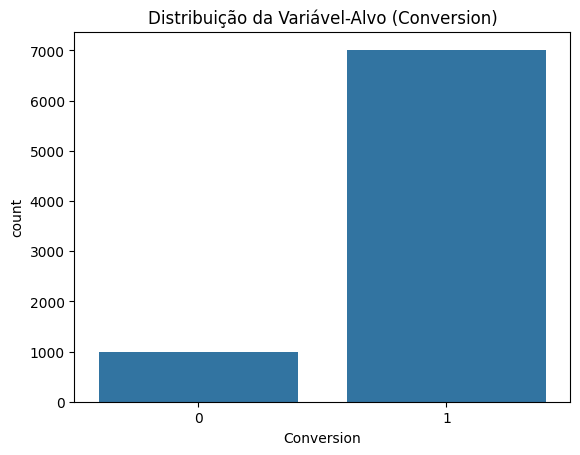

In [ ]:
sns.countplot(data=df_mkd, x='Conversion')
plt.title('Distribuição da Variável-Alvo (Conversion)')
plt.show()


A variável-alvo Conversion está desbalanceada: 87,65% dos clientes converteram (classe 1) e apenas 12,35% não converteram (classe 0). Ou seja, a classe rara aqui é o "não converteu" — o oposto da maioria dos problemas de fraude, onde o evento raro é o positivo. Esse desbalanceamento é relevante porque um modelo que simplesmente "chutasse sempre conversão" já acertaria ~88%, o que torna a acurácia uma métrica enganosa. Por isso, na modelagem (Etapa 2), será importante usar métricas como recall, precisão e F1 voltadas à classe minoritária (não converteu) e considerar técnicas de balanceamento, para que o modelo realmente aprenda a identificar quem NÃO converte.

#Bloco 7
##Análise de relações e correlações entre variáveis

In [ ]:
df_mkd.corr(numeric_only=True)['Conversion']

,Conversion
CustomerID,-0.180742
Age,0.001606
Income,0.013974
AdSpend,0.124672
ClickThroughRate,0.120012
ConversionRate,0.093185
WebsiteVisits,0.079339
PagesPerVisit,0.102840
TimeOnSite,0.129609
SocialShares,-0.011449


In [ ]:
numericas = df_mkd.select_dtypes(include='number').drop(columns=['CustomerID'])
numericas.corr()['Conversion'].sort_values(ascending=False)


,Conversion
Conversion,1.000000
TimeOnSite,0.129609
EmailClicks,0.129521
EmailOpens,0.124884
AdSpend,0.124672
ClickThroughRate,0.120012
PreviousPurchases,0.111781
PagesPerVisit,0.102840
LoyaltyPoints,0.095004
ConversionRate,0.093185


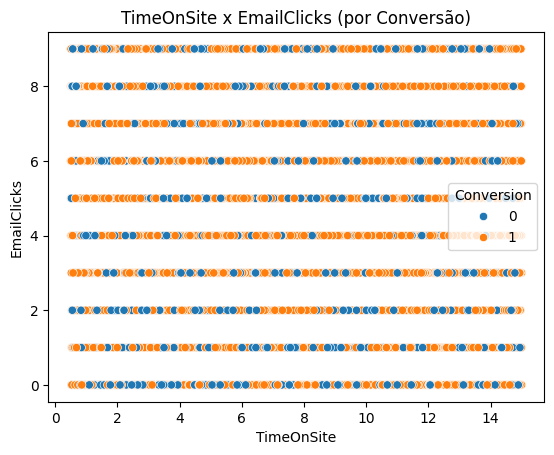

In [ ]:
sns.scatterplot(data=df_mkd, x='TimeOnSite', y='EmailClicks', hue='Conversion')
plt.title('TimeOnSite x EmailClicks (por Conversão)')
plt.show()


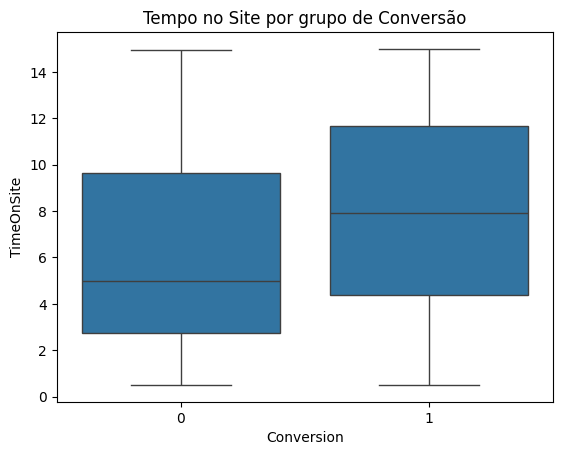

In [ ]:
sns.boxplot(data=df_mkd, x='Conversion', y='TimeOnSite')
plt.title('Tempo no Site por grupo de Conversão')
plt.show()


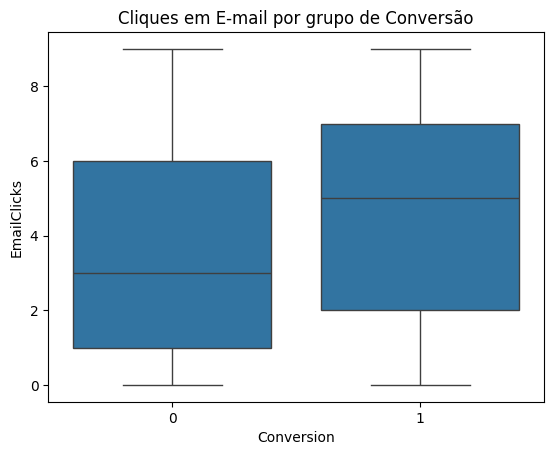

In [ ]:
sns.boxplot(data=df_mkd, x='Conversion', y='EmailClicks')
plt.title('Cliques em E-mail por grupo de Conversão')
plt.show()

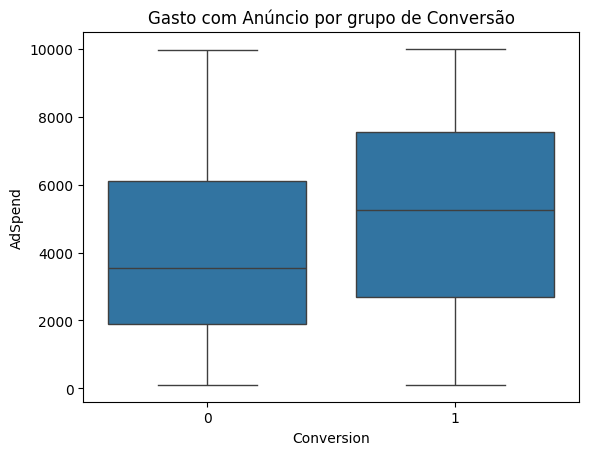

In [ ]:
sns.boxplot(data=df_mkd, x='Conversion', y='AdSpend')
plt.title('Gasto com Anúncio por grupo de Conversão')
plt.show()

In [ ]:
df_mkd.groupby('CampaignType')['Conversion'].mean().sort_values(ascending=False)

,Conversion
CampaignType,
Conversion,0.933558
Retention,0.858243
Consideration,0.855634
Awareness,0.855634


In [ ]:
df_mkd.groupby('CampaignChannel')['Conversion'].mean().sort_values(ascending=False)

,Conversion
CampaignChannel,
Referral,0.883072
PPC,0.882779
SEO,0.876774
Email,0.870263
Social Media,0.868334


In [ ]:
df_mkd.groupby('Gender')['Conversion'].mean().sort_values(ascending=False)

,Conversion
Gender,
Male,0.876938
Female,0.876214


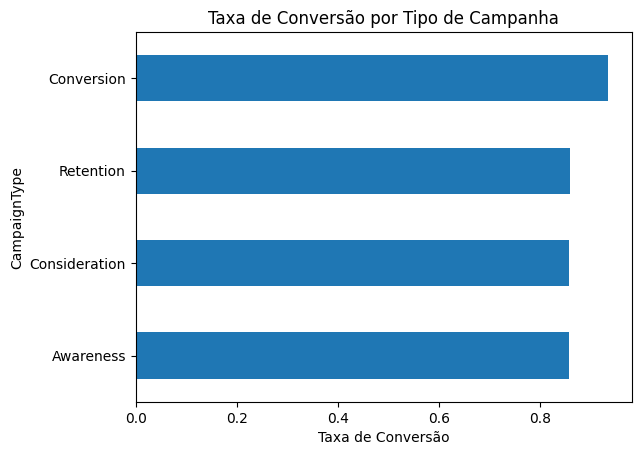

In [ ]:
df_mkd.groupby('CampaignType')['Conversion'].mean().sort_values().plot(kind='barh')
plt.title('Taxa de Conversão por Tipo de Campanha')
plt.xlabel('Taxa de Conversão')
plt.show()

As correlações numéricas com a Conversion são todas fracas; as maiores são TimeOnSite, EmailClicks, EmailOpens e AdSpend (todas ~0,12–0,13), e os boxplots confirmam que quem converte tende a se engajar um pouco mais, mas com muita sobreposição entre os grupos. Já nas variáveis categóricas, o tipo de campanha faz diferença: campanhas do tipo "Conversion" convertem 93,4%, contra ~85% das demais. Em contrapartida, o canal da campanha (diferença de ~1,5 pp) e o gênero (diferença de ~0,07 pp) praticamente não afetam a conversão. Conclusão do bloco: a conversão depende mais do engajamento do cliente e do tipo de campanha do que de características demográficas ou do canal utilizado.

#Bloco 8
##Remoção do identificador (CustumerID)

In [ ]:
df_prep = df_mkd.drop(columns=['CustomerID']).copy()
print(df_prep.shape)   # esperado: (8000, 17)

(8000, 17)


O CustomerID é apenas um número de identificação e não descreve o cliente. No Bloco 7 ele apresentou correlação de -0,18 com a Conversion, maior que a de qualquer variável real. Isso indica um padrão ligado apenas à ordem dos registros na base. Se fosse mantido, o modelo aprenderia uma regra falsa que não funcionaria para clientes novos. Por isso foi removido. Trabalhamos a partir de agora com uma cópia (df_prep), preservando a base original.

#Bloco 9
##Definição da variável-alvo + Codificação das variáveis categóricas

In [ ]:
# 1 = NÃO converteu (classe rara, que queremos identificar) | 0 = converteu
df_prep['NaoConverteu'] = (df_prep['Conversion'] == 0).astype(int)
df_prep = df_prep.drop(columns=['Conversion'])

print(df_prep['NaoConverteu'].value_counts())
print(df_prep['NaoConverteu'].value_counts(normalize=True) * 100)

NaoConverteu
0    7012
1     988
Name: count, dtype: int64
NaoConverteu
0    87.65
1    12.35
Name: proportion, dtype: float64


In [ ]:
colunas_categoricas = ['Gender', 'CampaignChannel', 'CampaignType']

df_cod = pd.get_dummies(df_prep, columns=colunas_categoricas, drop_first=True, dtype=int)

print(df_cod.shape)
print(df_cod.columns.tolist())
df_cod.head()

(8000, 22)
['Age', 'Income', 'AdSpend', 'ClickThroughRate', 'ConversionRate', 'WebsiteVisits', 'PagesPerVisit', 'TimeOnSite', 'SocialShares', 'EmailOpens', 'EmailClicks', 'PreviousPurchases', 'LoyaltyPoints', 'NaoConverteu', 'Gender_Male', 'CampaignChannel_PPC', 'CampaignChannel_Referral', 'CampaignChannel_SEO', 'CampaignChannel_Social Media', 'CampaignType_Consideration', 'CampaignType_Conversion', 'CampaignType_Retention']


,Age,Income,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,...,LoyaltyPoints,NaoConverteu,Gender_Male,CampaignChannel_PPC,CampaignChannel_Referral,CampaignChannel_SEO,CampaignChannel_Social Media,CampaignType_Consideration,CampaignType_Conversion,CampaignType_Retention
0,56,136912,6497.870068,0.043919,0.088031,0,2.399017,7.396803,19,6,...,688,0,0,0,0,0,1,0,0,0
1,69,41760,3898.668606,0.155725,0.182725,42,2.917138,5.352549,5,2,...,3459,0,1,0,0,0,0,0,0,1
2,46,88456,1546.429596,0.277490,0.076423,2,8.223619,13.794901,0,11,...,2337,0,0,1,0,0,0,0,0,0
3,32,44085,539.525936,0.137611,0.088004,47,4.540939,14.688363,89,2,...,2463,0,0,1,0,0,0,0,1,0
4,60,83964,1678.043573,0.252851,0.109940,0,2.046847,13.993370,6,6,...,4345,0,0,1,0,0,0,0,1,0


> **Alvo:** invertemos a variável para que a classe 1 seja “não converteu”. Ela é a classe rara (12,35%) e a que mais interessa ao negócio, porque identificar quem não vai converter permite agir antes. Assim, métricas como precisão, recall e F1 passam a medir diretamente a capacidade do modelo de encontrar esses clientes. Isso também bate com o front-end, que mostra a chance de não converter.
>
>
> **Codificação:** modelos de IA só trabalham com números, então as colunas de texto (Gender, CampaignChannel, CampaignType) foram transformadas com One-Hot Encoding. Cada categoria vira uma coluna de 0 ou 1. Usamos `drop_first=True` para eliminar uma categoria de cada variável, que fica representada quando todas as outras são 0. Isso evita informação redundante. Exemplo: `Gender_Male = 0` significa Female. A base ficou com [preencher] colunas. A codificação pode ser feita antes da separação porque não usa nenhuma estatística dos dados, então não há vazamento.
>

#Bloco 10
##Seleção dos atributos

In [ ]:
X = df_cod.drop(columns=['NaoConverteu'])
y = df_cod['NaoConverteu']

print("Quantidade de atributos:", X.shape[1])
print(X.columns.tolist())

Quantidade de atributos: 21
['Age', 'Income', 'AdSpend', 'ClickThroughRate', 'ConversionRate', 'WebsiteVisits', 'PagesPerVisit', 'TimeOnSite', 'SocialShares', 'EmailOpens', 'EmailClicks', 'PreviousPurchases', 'LoyaltyPoints', 'Gender_Male', 'CampaignChannel_PPC', 'CampaignChannel_Referral', 'CampaignChannel_SEO', 'CampaignChannel_Social Media', 'CampaignType_Consideration', 'CampaignType_Conversion', 'CampaignType_Retention']


> Decidimos manter todos os atributos nesta primeira versão. A EDA mostrou que Age, Income, Gender, SocialShares e CampaignChannel têm pouca relação com a conversão. Mesmo assim, a correlação mede apenas relações lineares, e modelos baseados em árvores podem encontrar combinações entre variáveis que a correlação não revela. Como a base tem poucas colunas, mantê-las não traz custo relevante. Na fase de modelagem, vamos testar se a remoção dessas variáveis fracas altera o desempenho.
>
>
> **Ponto de atenção:** a variável ConversionRate representa uma taxa de conversão. Pode ser discutido se essa informação estaria disponível antes de sabermos se o cliente converteu (possível vazamento de informação). Registramos isso como uma limitação a ser avaliada.
>

#Bloco 11
##Separação em treino, validação e teste (70/15/15)

In [ ]:
from sklearn.model_selection import train_test_split

# 1ª divisão: 70% treino | 30% restante
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)

# 2ª divisão: o restante é dividido ao meio -> 15% validação | 15% teste
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

for nome, yy in [('Treino', y_train), ('Validação', y_val), ('Teste', y_test)]:
    print(f"{nome}: {len(yy)} registros | {yy.mean()*100:.2f}% não converteram")

Treino: 5600 registros | 12.36% não converteram
Validação: 1200 registros | 12.33% não converteram
Teste: 1200 registros | 12.33% não converteram


Dividimos a base em três partes: treino (70%), usado para o modelo aprender; validação (15%), usada para comparar os modelos e escolher o melhor; e teste (15%), guardado até o final para medir o desempenho real em dados nunca vistos. O parâmetro stratify garante a mesma proporção de “não converteu” nos três conjuntos (cerca de 12%). O random_state=42 garante que a divisão seja sempre a mesma, para que todos do grupo trabalhem com os mesmos dados. A separação foi feita antes da normalização e do balanceamento para evitar vazamento de dados.

#Bloco 12
##Padronização das variáveis numéricas

In [ ]:
from sklearn.preprocessing import StandardScaler

colunas_numericas = ['Age', 'Income', 'AdSpend', 'ClickThroughRate', 'ConversionRate',
                     'WebsiteVisits', 'PagesPerVisit', 'TimeOnSite', 'SocialShares',
                     'EmailOpens', 'EmailClicks', 'PreviousPurchases', 'LoyaltyPoints']

X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

scaler = StandardScaler()
X_train[colunas_numericas] = scaler.fit_transform(X_train[colunas_numericas])  # aprende SÓ com o treino
X_val[colunas_numericas] = scaler.transform(X_val[colunas_numericas])          # apenas aplica
X_test[colunas_numericas] = scaler.transform(X_test[colunas_numericas])        # apenas aplica

print(X_train[colunas_numericas].describe().loc[['mean', 'std']].round(2))

      Age  Income  AdSpend  ClickThroughRate  ConversionRate  WebsiteVisits  \
mean -0.0     0.0      0.0              -0.0             0.0            0.0   
std   1.0     1.0      1.0               1.0             1.0            1.0   

      PagesPerVisit  TimeOnSite  SocialShares  EmailOpens  EmailClicks  \
mean            0.0        -0.0          -0.0        -0.0          0.0   
std             1.0         1.0           1.0         1.0          1.0   

      PreviousPurchases  LoyaltyPoints  
mean               -0.0            0.0  
std                 1.0            1.0  


As variáveis numéricas estão em escalas muito diferentes: Income vai de cerca de 20 mil a 150 mil, enquanto ClickThroughRate fica entre 0,01 e 0,30. Sem ajuste, modelos como a Regressão Logística dariam peso exagerado às variáveis com números maiores. Aplicamos a padronização (StandardScaler), que deixa cada variável com média 0 e desvio padrão 1, como mostra a tabela acima. As colunas criadas pelo One-Hot já são 0/1 e não foram alteradas. O scaler aprendeu a média e o desvio apenas com o treino (fit_transform) e depois aplicou esses mesmos valores à validação e ao teste (transform). Assim, nenhuma informação dos dados de avaliação influenciou o treinamento.

#Bloco 13
##Tratamento do desbalanceamento (somente no treino)

ANTES : {0: 4908, 1: 692}
DEPOIS: {1: 4908, 0: 4908}


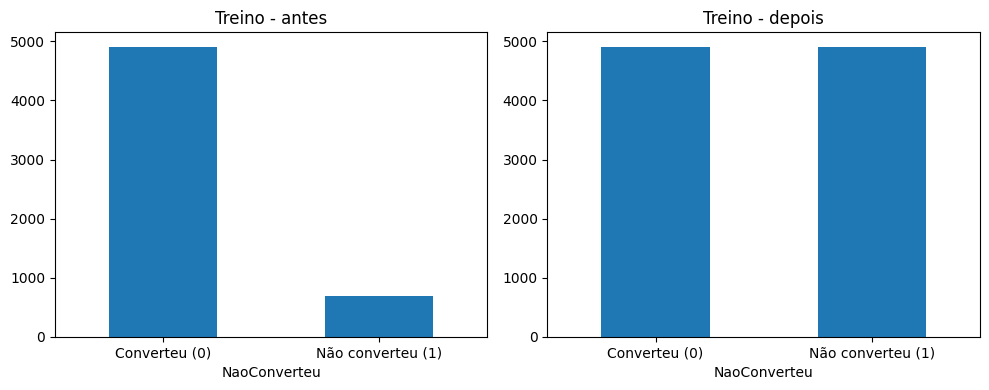

In [ ]:
!pip install -q imbalanced-learn
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)
X_train_bal, y_train_bal = ros.fit_resample(X_train, y_train)

print("ANTES :", y_train.value_counts().to_dict())
print("DEPOIS:", y_train_bal.value_counts().to_dict())

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
y_train.value_counts().sort_index().plot(kind='bar', ax=ax[0], title='Treino - antes')
y_train_bal.value_counts().sort_index().plot(kind='bar', ax=ax[1], title='Treino - depois')
for a in ax:
    a.set_xticklabels(['Converteu (0)', 'Não converteu (1)'], rotation=0)
plt.tight_layout()
plt.show()

Com apenas cerca de 12% de “não converteu”, um modelo tende a ignorar essa classe e prever sempre “converteu”. Para corrigir, aplicamos oversampling aleatório (RandomOverSampler), que repete exemplos da classe minoritária até as duas classes ficarem com a mesma quantidade no treino ([preencher] de cada). Escolhemos essa técnica por ser simples e não criar dados artificiais. O balanceamento foi aplicado somente no treino. Validação e teste mantêm a proporção real (88/12), porque representam a situação real em que o modelo será usado. Alternativas que podem ser testadas na modelagem: o parâmetro class_weight='balanced' dos modelos ou a técnica SMOTE.

#Bloco 14
##Salvando os conjuntos preparados

In [ ]:
import os, json, joblib

pasta = 'dados_preparados'
os.makedirs(pasta, exist_ok=True)

X_train_bal.to_csv(f'{pasta}/X_train_bal.csv', index=False)
y_train_bal.to_csv(f'{pasta}/y_train_bal.csv', index=False)
X_train.to_csv(f'{pasta}/X_train.csv', index=False)   # treino sem balancear (para quem usar class_weight)
y_train.to_csv(f'{pasta}/y_train.csv', index=False)
X_val.to_csv(f'{pasta}/X_val.csv', index=False)
y_val.to_csv(f'{pasta}/y_val.csv', index=False)
X_test.to_csv(f'{pasta}/X_test.csv', index=False)
y_test.to_csv(f'{pasta}/y_test.csv', index=False)

joblib.dump(scaler, f'{pasta}/scaler.pkl')   # será usado na aplicação final
with open(f'{pasta}/colunas.json', 'w') as f:
    json.dump({'atributos': X.columns.tolist(), 'numericas': colunas_numericas}, f, indent=2)

!zip -r -q dados_preparados.zip dados_preparados
from google.colab import files
files.download('dados_preparados.zip')

NameError: name 'X_train_bal' is not defined

Os conjuntos foram salvos para que todos os integrantes treinem seus modelos exatamente com os mesmos dados. O scaler.pkl e a lista de colunas também foram salvos, porque a aplicação final precisa aplicar a mesma transformação aos dados digitados pelo usuário antes de enviá-los ao modelo.
Atenção: os arquivos criados no Colab somem quando a sessão termina. Baixe o .zip antes de fechar a aba.

Bloco reiniciar

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import RandomOverSampler

# 1. Carregar a base (do GitHub, como vocês fizeram no início)
URL_BASE = "https://raw.githubusercontent.com/williamasantos/Agente-de-Previsao-de-Conversao/refs/heads/preparacao-dados/digital_marketing_campaign_dataset.csv"
df_mkd = pd.read_csv(URL_BASE)

# 2. Limpeza (remover colunas inúteis e o ID)
df_mkd = df_mkd.drop(columns=['AdvertisingPlatform', 'AdvertisingTool', 'CustomerID'], errors='ignore')

# 3. Separar X e y
X = df_mkd.drop(columns=['Conversion'])
y = df_mkd['Conversion']

# 4. Separar Treino (70%), Validação (15%) e Teste (15%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

# 5. Padronização (StandardScaler)
colunas_numericas = ['Age', 'Income', 'AdSpend', 'ClickThroughRate', 'ConversionRate',
                     'WebsiteVisits', 'PagesPerVisit', 'TimeOnSite', 'SocialShares',
                     'EmailOpens', 'EmailClicks', 'PreviousPurchases', 'LoyaltyPoints']

X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

scaler = StandardScaler()
X_train[colunas_numericas] = scaler.fit_transform(X_train[colunas_numericas])
X_val[colunas_numericas] = scaler.transform(X_val[colunas_numericas])
X_test[colunas_numericas] = scaler.transform(X_test[colunas_numericas])

# 6. Balanceamento (RandomOverSampler no treino)
ros = RandomOverSampler(random_state=42)
X_train_bal, y_train_bal = ros.fit_resample(X_train, y_train)

print("Ambiente recriado com sucesso!")
print(f"X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}")
print(f"X_train_bal: {X_train_bal.shape}")

Ambiente recriado com sucesso!
X_train: (5600, 16) | X_val: (1200, 16) | X_test: (1200, 16)
X_train_bal: (9816, 16)


 Bloco 15: Treinamento dos Modelos

 Modelo 1: K-NN (K-Nearest Neighbors)

 PREPARAÇÃO INICIAL (rode apenas uma vez)
 Removendo a ConversionRate para evitar vazamento

In [ ]:
X_train_final = X_train.drop(columns=['ConversionRate'], errors='ignore')
X_val_final = X_val.drop(columns=['ConversionRate'], errors='ignore')

Treinado Modelo 1_K-NN

In [ ]:
# Transformando variáveis categóricas (texto) em números (One-Hot Encoding)
X_train_final = pd.get_dummies(X_train_final, drop_first=True)
X_val_final = pd.get_dummies(X_val_final, drop_first=True)

# Garantindo que o treino e a validação tenham exatamente as mesmas colunas
X_train_final, X_val_final = X_train_final.align(X_val_final, join='left', axis=1, fill_value=0)

print(f"Colunas numéricas prontas para o modelo. Total de features: {X_train_final.shape[1]}")

Colunas numéricas prontas para o modelo. Total de features: 20


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

print("Treinando K-NN...")
knn = KNeighborsClassifier(n_neighbors=5, weights='distance')
knn.fit(X_train_final, y_train)

y_pred_knn = knn.predict(X_val_final)

print("\n=== Resultado do K-NN ===")
print(classification_report(y_val, y_pred_knn))

Treinando K-NN...

=== Resultado do K-NN ===
              precision    recall  f1-score   support

           0       0.56      0.12      0.20       148
           1       0.89      0.99      0.94      1052

    accuracy                           0.88      1200
   macro avg       0.73      0.55      0.57      1200
weighted avg       0.85      0.88      0.84      1200



MODELO 2: Naive Bayes

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report

print("Treinando Naive Bayes...")

nb = GaussianNB()
nb.fit(X_train_final, y_train)

y_pred_nb = nb.predict(X_val_final)

print("\n=== Resultado do Naive Bayes ===")
print(classification_report(y_val, y_pred_nb))

Treinando Naive Bayes...

=== Resultado do Naive Bayes ===
              precision    recall  f1-score   support

           0       0.76      0.11      0.19       148
           1       0.89      1.00      0.94      1052

    accuracy                           0.89      1200
   macro avg       0.82      0.55      0.56      1200
weighted avg       0.87      0.89      0.85      1200



 MODELO 3: Árvore de Decisão

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

print("Treinando Árvore de Decisão...")

dt = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)
dt.fit(X_train_final, y_train)

y_pred_dt = dt.predict(X_val_final)

print("\n=== Resultado da Árvore de Decisão ===")
print(classification_report(y_val, y_pred_dt))

Treinando Árvore de Decisão...

=== Resultado da Árvore de Decisão ===
              precision    recall  f1-score   support

           0       0.22      0.47      0.30       148
           1       0.91      0.77      0.83      1052

    accuracy                           0.73      1200
   macro avg       0.57      0.62      0.57      1200
weighted avg       0.83      0.73      0.77      1200



 MODELO 4: SVM (Support Vector Machine)

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report

print("Treinando SVM... (pode demorar um pouco)")

svm = SVC(kernel='rbf', class_weight='balanced', random_state=42)
svm.fit(X_train_final, y_train)

y_pred_svm = svm.predict(X_val_final)

print("\n=== Resultado do SVM ===")
print(classification_report(y_val, y_pred_svm))

Treinando SVM... (pode demorar um pouco)

=== Resultado do SVM ===
              precision    recall  f1-score   support

           0       0.33      0.53      0.41       148
           1       0.93      0.85      0.89      1052

    accuracy                           0.81      1200
   macro avg       0.63      0.69      0.65      1200
weighted avg       0.85      0.81      0.83      1200



 MODELO 5: Rede Neural (TensorFlow/Keras)

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.metrics import classification_report
from sklearn.utils import class_weight
import numpy as np

print("Treinando Rede Neural... (pode levar 1 ou 2 minutos)")

# 1. Calculando os pesos para balancear as classes (substitui o RandomOverSampler)
pesos = class_weight.compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
pesos_dict = {0: pesos[0], 1: pesos[1]}

# 2. Criando a estrutura da Rede Neural
# Duas camadas escondidas com 64 e 32 neurônios, usando a função 'relu'
modelo_rn = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_final.shape[1],)),
    Dropout(0.2), # Evita decoreba (overfitting)
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid') # Sigmoide para classificação binária (0 ou 1)
])

# 3. Compilando o modelo
modelo_rn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 4. Treinando o modelo
# verbose=0 esconde aquela barra de progresso que enche a tela
historico = modelo_rn.fit(X_train_final, y_train,
                          validation_data=(X_val_final, y_val),
                          epochs=20, batch_size=32,
                          class_weight=pesos_dict, verbose=0)

# 5. Fazendo previsões
y_pred_proba = modelo_rn.predict(X_val_final)
y_pred_rn = (y_pred_proba > 0.5).astype(int).flatten() # Transforma probabilidade em 0 ou 1

# 6. Avaliação
print("\n=== Resultado da Rede Neural ===")
print(classification_report(y_val, y_pred_rn))

Treinando Rede Neural... (pode levar 1 ou 2 minutos)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

=== Resultado da Rede Neural ===
              precision    recall  f1-score   support

           0       0.29      0.59      0.39       148
           1       0.93      0.79      0.86      1052

    accuracy                           0.77      1200
   macro avg       0.61      0.69      0.62      1200
weighted avg       0.85      0.77      0.80      1200



TESTE FINAL: Avaliando na base de Teste (dados nunca vistos)

In [ ]:
from sklearn.metrics import classification_report

# 1. Preparando o X_test (mesmo processo que fizemos no treino)
X_test_final = X_test.drop(columns=['ConversionRate'], errors='ignore')
X_test_final = pd.get_dummies(X_test_final, drop_first=True)

# Alinhando as colunas do teste com as do treino (para não dar erro de colunas faltando)
X_test_final = X_test_final.reindex(columns=X_train_final.columns, fill_value=0)

print("="*50)
print("TESTE 1: SVM (Support Vector Machine)")
print("="*50)
y_pred_svm_test = svm.predict(X_test_final)
print(classification_report(y_test, y_pred_svm_test))

print("\n" + "="*50)
print("TESTE 2: Rede Neural")
print("="*50)
# Fazendo a previsão com a Rede Neural
y_pred_proba_rn_test = modelo_rn.predict(X_test_final, verbose=0)
y_pred_rn_test = (y_pred_proba_rn_test > 0.5).astype(int).flatten()
print(classification_report(y_test, y_pred_rn_test))

TESTE 1: SVM (Support Vector Machine)
              precision    recall  f1-score   support

           0       0.33      0.57      0.41       148
           1       0.93      0.83      0.88      1052

    accuracy                           0.80      1200
   macro avg       0.63      0.70      0.65      1200
weighted avg       0.86      0.80      0.82      1200


TESTE 2: Rede Neural
              precision    recall  f1-score   support

           0       0.30      0.65      0.41       148
           1       0.94      0.79      0.86      1052

    accuracy                           0.77      1200
   macro avg       0.62      0.72      0.63      1200
weighted avg       0.86      0.77      0.80      1200



Gráfico Comparativo

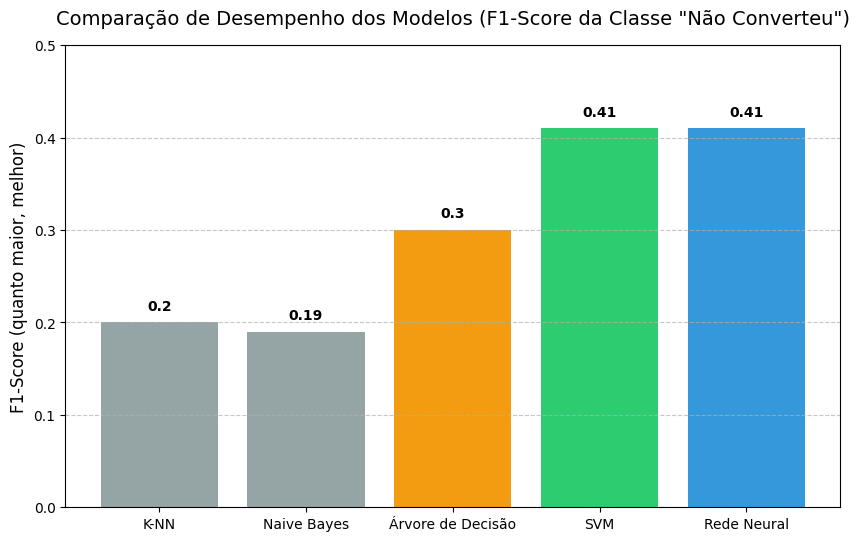

In [ ]:
import matplotlib.pyplot as plt

# Resultados coletados (F1-score da classe 0 - Não converteu)
modelos = ['K-NN', 'Naive Bayes', 'Árvore de Decisão', 'SVM', 'Rede Neural']
f1_scores = [0.20, 0.19, 0.30, 0.41, 0.41]
cores = ['#95a5a6', '#95a5a6', '#f39c12', '#2ecc71', '#3498db']

plt.figure(figsize=(10, 6))
bars = plt.bar(modelos, f1_scores, color=cores)

# Adicionando os valores em cima das barras
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, round(yval, 2), ha='center', va='bottom', fontweight='bold')

plt.title('Comparação de Desempenho dos Modelos (F1-Score da Classe "Não Converteu")', fontsize=14, pad=15)
plt.ylabel('F1-Score (quanto maior, melhor)', fontsize=12)
plt.ylim(0, 0.5)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Gráfico 1: Matriz de Confusão (O Mapa do Acerto)

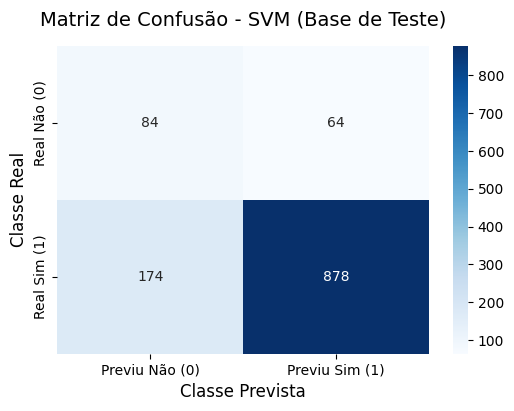

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Usando as previsões do SVM no teste (que foi o nosso campeão)
cm = confusion_matrix(y_test, y_pred_svm_test)

plt.figure(figsize=(6, 4))
# annot=True coloca os números dentro dos quadrados
# fmt='d' garante que os números sejam inteiros (sem casas decimais)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Previu Não (0)', 'Previu Sim (1)'],
            yticklabels=['Real Não (0)', 'Real Sim (1)'])

plt.title('Matriz de Confusão - SVM (Base de Teste)', fontsize=14, pad=15)
plt.ylabel('Classe Real', fontsize=12)
plt.xlabel('Classe Prevista', fontsize=12)
plt.show()

Gráfico 2: Curva ROC e AUC (O Poder de Separação)

38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


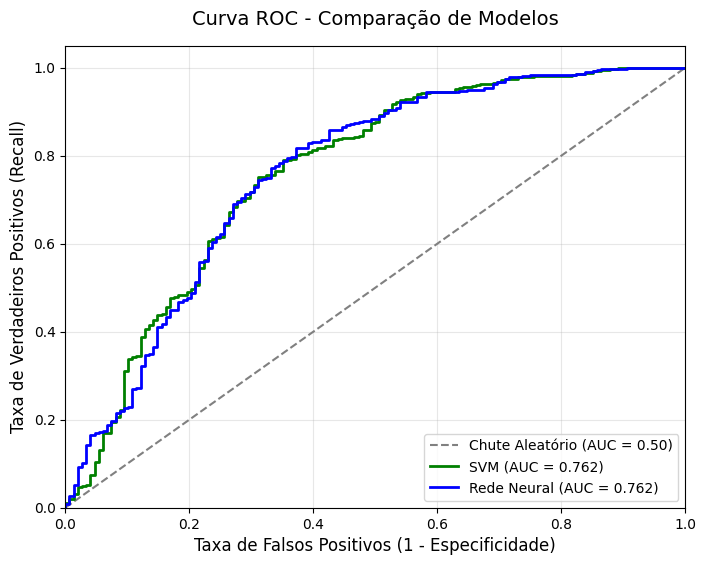

In [ ]:
from sklearn.metrics import roc_curve, auc

# Precisamos das probabilidades, não apenas do 0 ou 1
# (Se o SVM não tiver predict_proba, precisamos do decision_function)
y_proba_svm = svm.decision_function(X_test_final)
y_proba_rn = modelo_rn.predict(X_test_final).ravel()

# Calculando as curvas
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_proba_svm)
fpr_rn, tpr_rn, _ = roc_curve(y_test, y_proba_rn)

# Calculando a área sob a curva (AUC)
auc_svm = auc(fpr_svm, tpr_svm)
auc_rn = auc(fpr_rn, tpr_rn)

plt.figure(figsize=(8, 6))
# Plotando a linha do chute aleatório
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Chute Aleatório (AUC = 0.50)')
# Plotando as curvas dos modelos
plt.plot(fpr_svm, tpr_svm, color='green', lw=2, label=f'SVM (AUC = {auc_svm:.3f})')
plt.plot(fpr_rn, tpr_rn, color='blue', lw=2, label=f'Rede Neural (AUC = {auc_rn:.3f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos (1 - Especificidade)', fontsize=12)
plt.ylabel('Taxa de Verdadeiros Positivos (Recall)', fontsize=12)
plt.title('Curva ROC - Comparação de Modelos', fontsize=14, pad=15)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

Gráfico 3: Distribuição da Variável Alvo (EDA)

/tmp/ipykernel_593/1380516712.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Conversion', data=df_mkd, palette=['#e74c3c', '#2ecc71'])


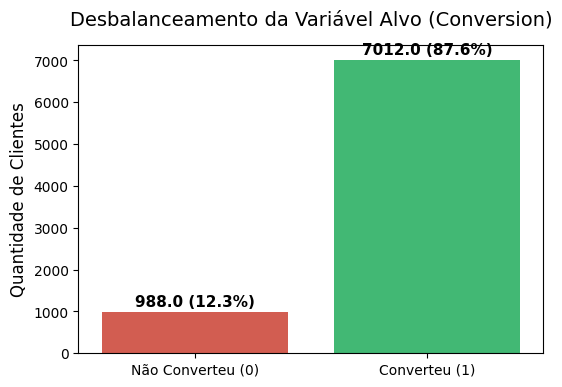

In [ ]:
plt.figure(figsize=(6, 4))
# Usando o df_mkd original (antes das transformações)
sns.countplot(x='Conversion', data=df_mkd, palette=['#e74c3c', '#2ecc71'])

plt.title('Desbalanceamento da Variável Alvo (Conversion)', fontsize=14, pad=15)
plt.xticks([0, 1], ['Não Converteu (0)', 'Converteu (1)'])
plt.ylabel('Quantidade de Clientes', fontsize=12)
plt.xlabel('')

# Adicionando os valores em cima das barras
total = len(df_mkd)
for p in plt.gca().patches:
    height = p.get_height()
    plt.gca().text(p.get_x() + p.get_width()/2, height + 50,
                   f'{height} ({height/total*100:.1f}%)',
                   ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.show()

 Gráfico 4: Importância das Variáveis

/tmp/ipykernel_593/1060875172.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia', y='Variavel', data=df_importancia, palette='viridis')


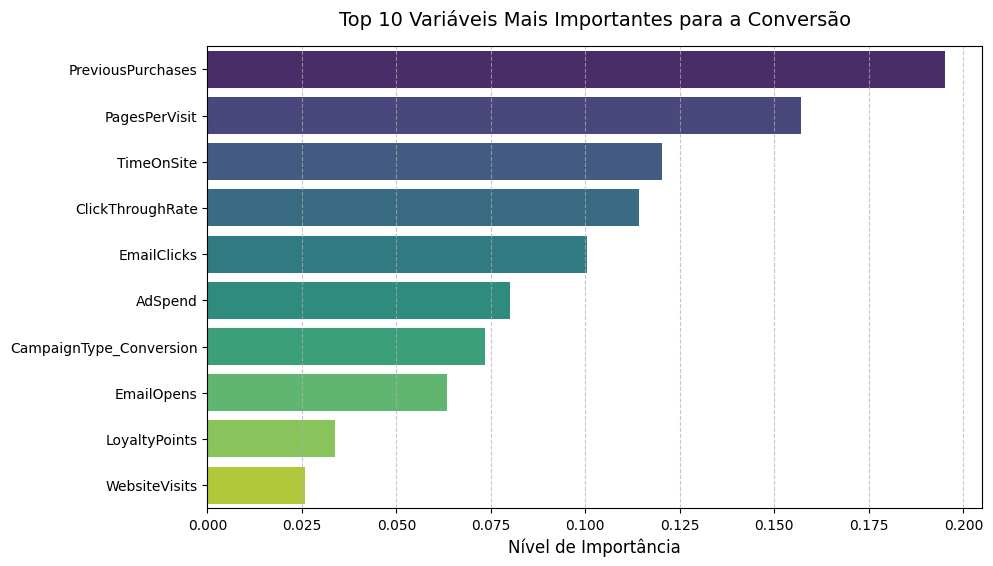

In [ ]:
# Vamos treinar uma Árvore de Decisão rapidinho só para extrair a importância
from sklearn.tree import DecisionTreeClassifier

dt_importancia = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)
dt_importancia.fit(X_train_final, y_train)

# Pegando os nomes das colunas e as importâncias
importancias = dt_importancia.feature_importances_
nomes_colunas = X_train_final.columns

# Criando um DataFrame para organizar e pegar as 10 mais importantes
df_importancia = pd.DataFrame({'Variavel': nomes_colunas, 'Importancia': importancias})
df_importancia = df_importancia.sort_values(by='Importancia', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variavel', data=df_importancia, palette='viridis')

plt.title('Top 10 Variáveis Mais Importantes para a Conversão', fontsize=14, pad=15)
plt.xlabel('Nível de Importância', fontsize=12)
plt.ylabel('')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()